# Prédiction du prix des Airbnb à Paris

Nom :

Dans ce notebook on reprend tout le projet du groupe (EDA, feature engineering, pipeline et modèles) dans un seul fichier et on corrige plusieurs problèmes qu'on a trouvés en relisant le code :

1. Le prix : les prix au dessus de 1000 € s'écrivent avec une virgule ("$1,386.50"), du coup la conversion en float donnait des NaN et ces logements étaient supprimés avec les prix manquants.
2. La distance au métro était calculée avec une distance euclidienne sur la latitude/longitude, ce qui fausse les distances. On utilise la distance haversine.
3. Le fichier des gares contient toutes les gares (train, RER, tram, métro), on fait une variable pour le métro et une pour toutes les gares.
4. Les amenities sont lues avec json au lieu de faire des replace.
5. Les bedrooms manquants étaient remplacés par 1, on prend la médiane selon accommodates comme pour les lits.
6. On regroupe les property_type rares dans le one hot encoding.
7. On ajoute la distance au centre de Paris.
8. On ajoute une analyse des erreurs du modèle.
9. On ajoute des nouvelles variables qu'on n'utilisait pas : le nombre de salles de bain, la surface en m2 qu'on trouve dans les descriptions, l'ancienneté de l'annonce...
10. On utilise le texte des annonces (titre et description) avec un TF-IDF.

Le notebook doit être à la racine du projet, à côté du dossier data.

## Imports

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.spatial import cKDTree
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.neighbors import BallTree
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict, KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, median_absolute_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# le dossier raw peut être dans data/ ou directement à côté du notebook
if Path("data/raw").exists():
    chemin_raw = Path("data/raw")
else:
    chemin_raw = Path("raw")

chemin_airbnb = chemin_raw / "airbnb"
chemin_poi = chemin_raw / "poi"
print("Données lues dans :", chemin_airbnb)
chemin_sauvegarde = Path("data/processed")
chemin_sauvegarde.mkdir(parents=True, exist_ok=True)

Données lues dans : data/raw/airbnb


## Chargement des données

On garde seulement les colonnes utiles. On ne prend pas les colonnes calculées à partir du prix (estimated_revenue_l365d, price_quote...) sinon le modèle aurait déjà la réponse.

In [2]:
df_brut = pd.read_parquet(chemin_airbnb / "listings_detailled.parquet")
print("Le dataset contient", df_brut.shape[0], "lignes et", df_brut.shape[1], "colonnes")

colonnes_a_garder = [
    'id', 'property_type', 'room_type', 'accommodates', 'bedrooms', 'beds', 'amenities',
    'latitude', 'longitude', 'neighbourhood_cleansed', 'price', 'minimum_nights', 'maximum_nights',
    'host_is_superhost', 'host_identity_verified', 'host_listings_count', 'hosts_time_as_host_years',
    'number_of_reviews', 'number_of_reviews_ltm', 'reviews_per_month', 'review_scores_rating',
    'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
    'review_scores_communication', 'review_scores_location', 'review_scores_value',
    'availability_30', 'availability_60', 'availability_90', 'availability_365',
    'bathrooms_text', 'name', 'description', 'first_review', 'estimated_occupancy_l365d',
    'minimum_nights_avg_ntm', 'calculated_host_listings_count_entire_homes', 'number_of_reviews_l30d'
]
df = df_brut[colonnes_a_garder].copy()
df.head(3)

Le dataset contient 77149 lignes et 90 colonnes


,id,property_type,room_type,accommodates,bedrooms,beds,amenities,latitude,longitude,neighbourhood_cleansed,price,minimum_nights,maximum_nights,host_is_superhost,host_identity_verified,host_listings_count,hosts_time_as_host_years,number_of_reviews,number_of_reviews_ltm,reviews_per_month,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,availability_30,availability_60,availability_90,availability_365,bathrooms_text,name,description,first_review,estimated_occupancy_l365d,minimum_nights_avg_ntm,calculated_host_listings_count_entire_homes,number_of_reviews_l30d
0,3109,Entire rental unit,Entire home/apt,2,1.0,1.0,"[""Iron"", ""Children\u2019s books and toys"", ""Sm...",48.83191,2.31870,Observatoire,$272.50,2.0,30.0,f,t,1,13.0,10,2,0.09,4.90,5.00,5.00,5.00,5.00,5.00,4.90,19,46,76,351,1 bath,zen and calm,Lovely Appartment with one bedroom with a Quee...,2017-10-28,21,2.0,1,0
1,7397,Entire rental unit,Entire home/apt,4,2.0,1.0,"[""Free washer \u2013 In unit"", ""Hot water"", ""R...",48.85909,2.35315,Hôtel-de-Ville,$149.40,10.0,130.0,f,t,1,15.0,403,18,2.14,4.72,4.80,4.45,4.92,4.90,4.94,4.74,0,10,37,216,1 bath,MARAIS - 2ROOMS APT - 2/4 PEOPLE,"VERY CONVENIENT, WITH THE BEST LOCATION !",2011-04-08,255,10.0,1,0
2,9952,Entire rental unit,Entire home/apt,2,1.0,1.0,"[""Hot water"", ""Refrigerator"", ""Wifi"", ""Dedicat...",48.86373,2.37093,Popincourt,$177.75,4.0,31.0,f,t,1,15.0,60,4,0.36,4.92,4.97,4.88,4.98,4.87,4.87,4.88,0,0,21,82,1 bath,Paris petit coin douillet,"I am a retired lady, who offers a pleasant lit...",2013-03-19,42,4.0,1,0


## Le prix

Le prix est une chaîne de caractères avec un $ devant. Dans la première version on enlevait seulement le $ mais on a vu que les prix au dessus de 1000 € ont une virgule pour les milliers ("$1,386.50"). pd.to_numeric renvoie NaN pour ces valeurs sans mettre d'erreur.

On compare les deux méthodes :

In [3]:
# ancienne méthode : on enlève juste le $
prix_ancien = pd.to_numeric(df['price'].astype(str).str.replace('$', '', regex=False), errors='coerce')

# nouvelle méthode : on enlève le $ et la virgule
prix_nouveau = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
prix_nouveau = pd.to_numeric(prix_nouveau, errors='coerce')

print("Prix lus avec l'ancienne méthode :", prix_ancien.notna().sum())
print("Prix lus avec la nouvelle méthode :", prix_nouveau.notna().sum())
print("Logements perdus avant :", prix_nouveau.notna().sum() - prix_ancien.notna().sum())
print("Prix max avant :", prix_ancien.max(), "/ maintenant :", prix_nouveau.max())

Prix lus avec l'ancienne méthode : 41959
Prix lus avec la nouvelle méthode : 43537
Logements perdus avant : 1578
Prix max avant : 999.5 / maintenant : 100666.1


Donc avant on perdait tous les logements à plus de 1000 €, c'est pour ça que le prix max était 999.5 €. Le modèle n'avait jamais vu de logement haut de gamme.

Les prix sont affichés avec un $ mais Inside Airbnb met la monnaie locale, donc ce sont des euros.

In [4]:
df['price'] = prix_nouveau
print("Nombre de prix manquants :", df['price'].isna().sum())

# on ne peut pas imputer la target donc on supprime
df = df.dropna(subset=['price'])
df['price'].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999])

Nombre de prix manquants : 33612


count     43537.000000
mean        337.195117
std         867.498711
min          10.380000
1%           46.510000
25%         139.000000
50%         218.000000
75%         359.000000
90%         603.350000
99%        1871.640000
99.9%      8377.906080
max      100666.100000
Name: price, dtype: float64

On regarde les prix les plus élevés :

In [5]:
df[df['price'] > 5000][['price', 'room_type', 'accommodates', 'bedrooms', 'neighbourhood_cleansed']].sort_values('price', ascending=False).head(8)

,price,room_type,accommodates,bedrooms,neighbourhood_cleansed
44189,100666.10,Entire home/apt,7,4.0,Batignolles-Monceau
52036,70080.00,Entire home/apt,6,3.0,Passy
29872,46789.00,Entire home/apt,2,1.0,Palais-Bourbon
5821,34536.67,Entire home/apt,2,1.0,Buttes-Chaumont
43301,22516.00,Entire home/apt,8,4.0,Palais-Bourbon
76597,21000.00,Entire home/apt,8,4.0,Élysée
56430,20132.00,Entire home/apt,10,5.0,Palais-Bourbon
67165,20032.50,Entire home/apt,4,2.0,Bourse


On a des appartements de 2 personnes à plus de 30 000 € la nuit, ce sont sûrement des erreurs ou des prix mis par l'hôte pour bloquer les réservations. On enlève les prix au dessus de 2000 € (à peu près le 99e centile), comme ça on garde quand même les vrais logements de luxe.

In [6]:
prix_max = 2000
print("Logements supprimés :", (df['price'] > prix_max).sum())
df = df[df['price'] <= prix_max].reset_index(drop=True)
print("Logements restants :", len(df))

Logements supprimés : 386


Logements restants : 43151


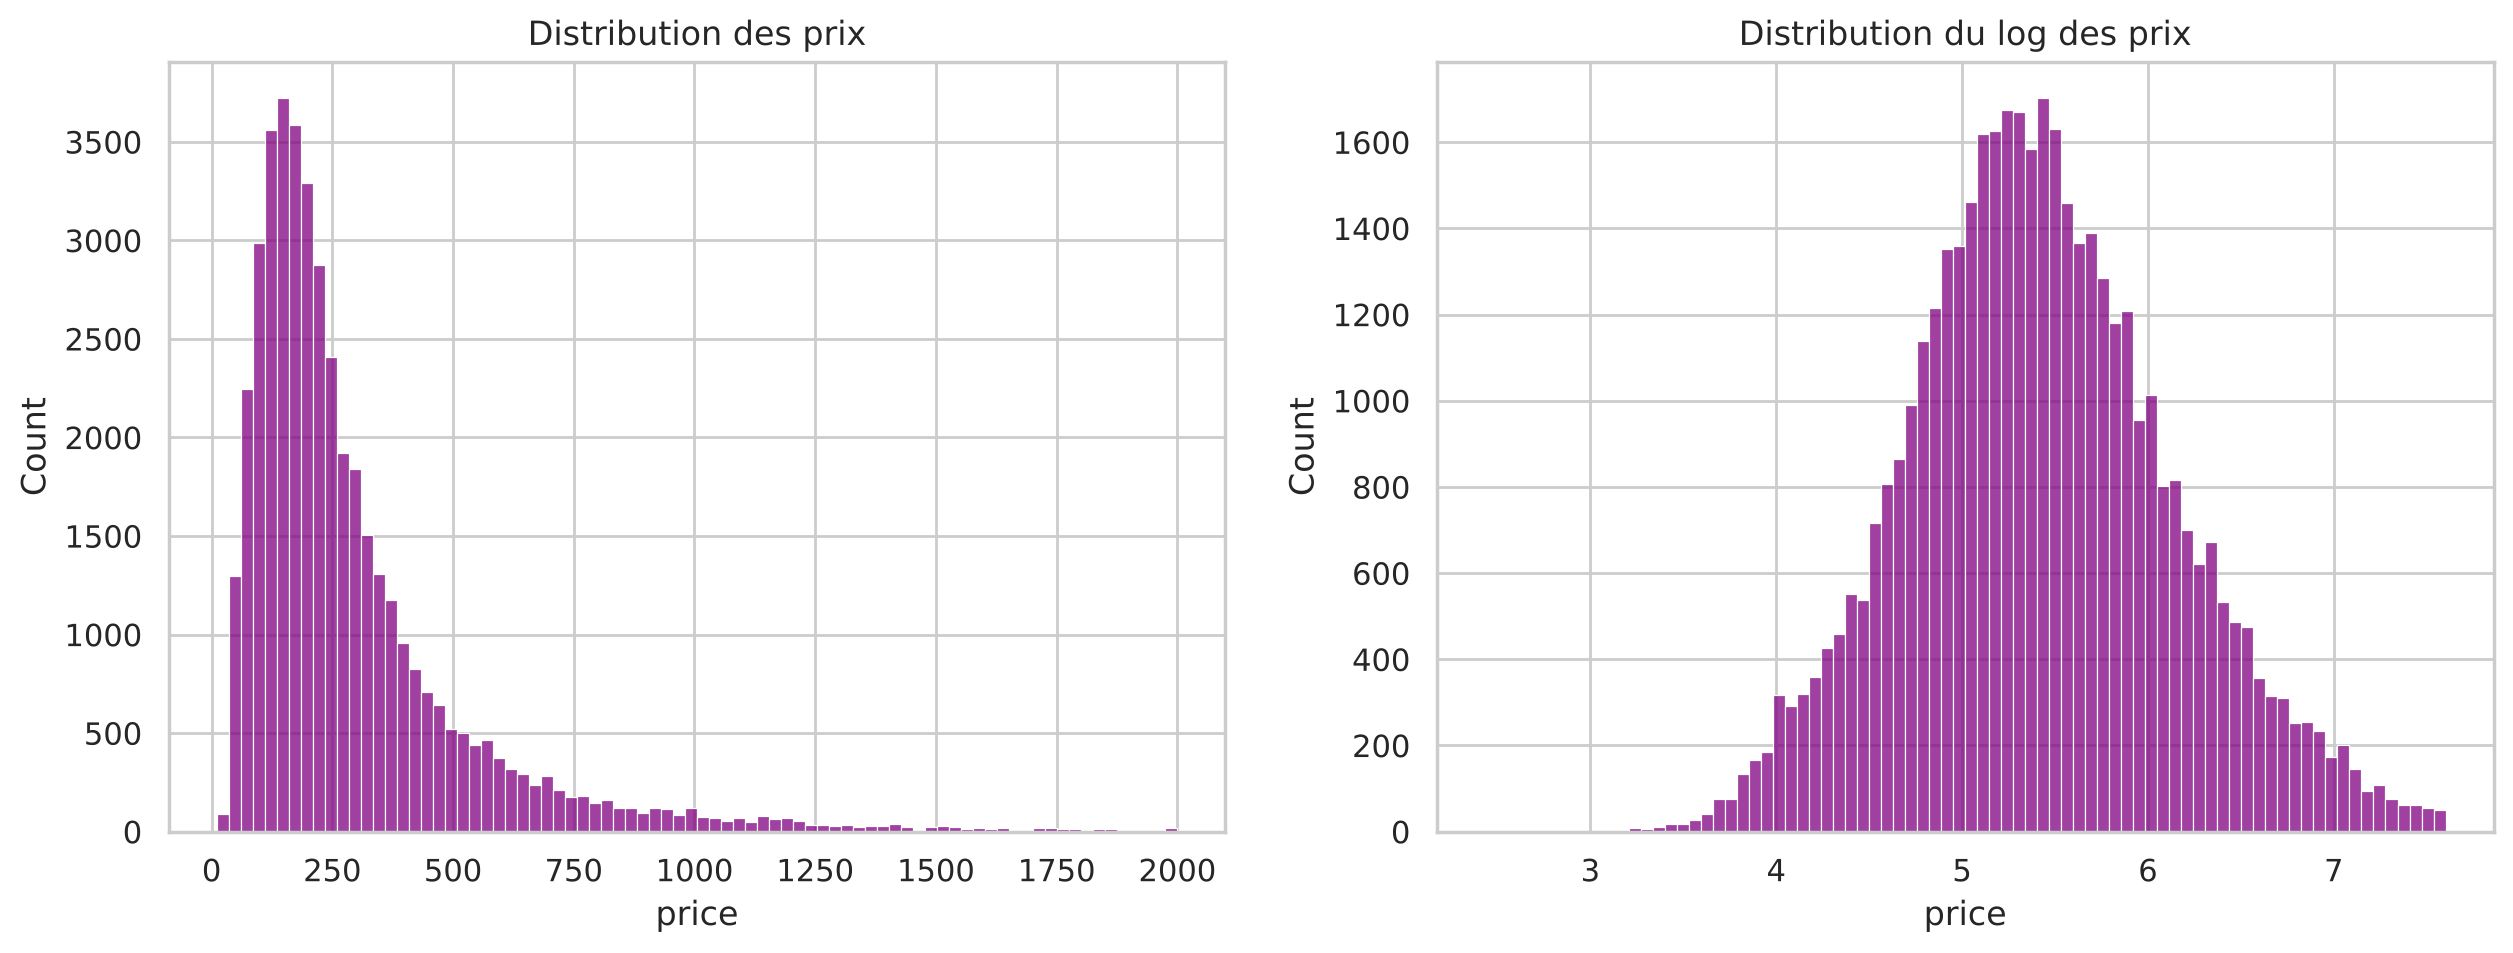

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df['price'], bins=80, ax=ax[0], color='purple')
ax[0].set_title('Distribution des prix')

sns.histplot(np.log1p(df['price']), bins=80, ax=ax[1], color='purple')
ax[1].set_title('Distribution du log des prix')

plt.show()

La distribution est très asymétrique, avec le log ça ressemble plus à une loi normale. On va donc prédire log1p(prix) et on repasse en euros avec expm1 pour calculer l'erreur.

## EDA

In [8]:
df.groupby('room_type')['price'].agg(['count', 'median', 'mean']).sort_values(by='median', ascending=False)

,count,median,mean
room_type,,,
Hotel room,278,337.9,432.975288
Entire home/apt,37805,225.0,301.976644
Private room,4950,156.0,221.515982
Shared room,118,58.0,95.214492


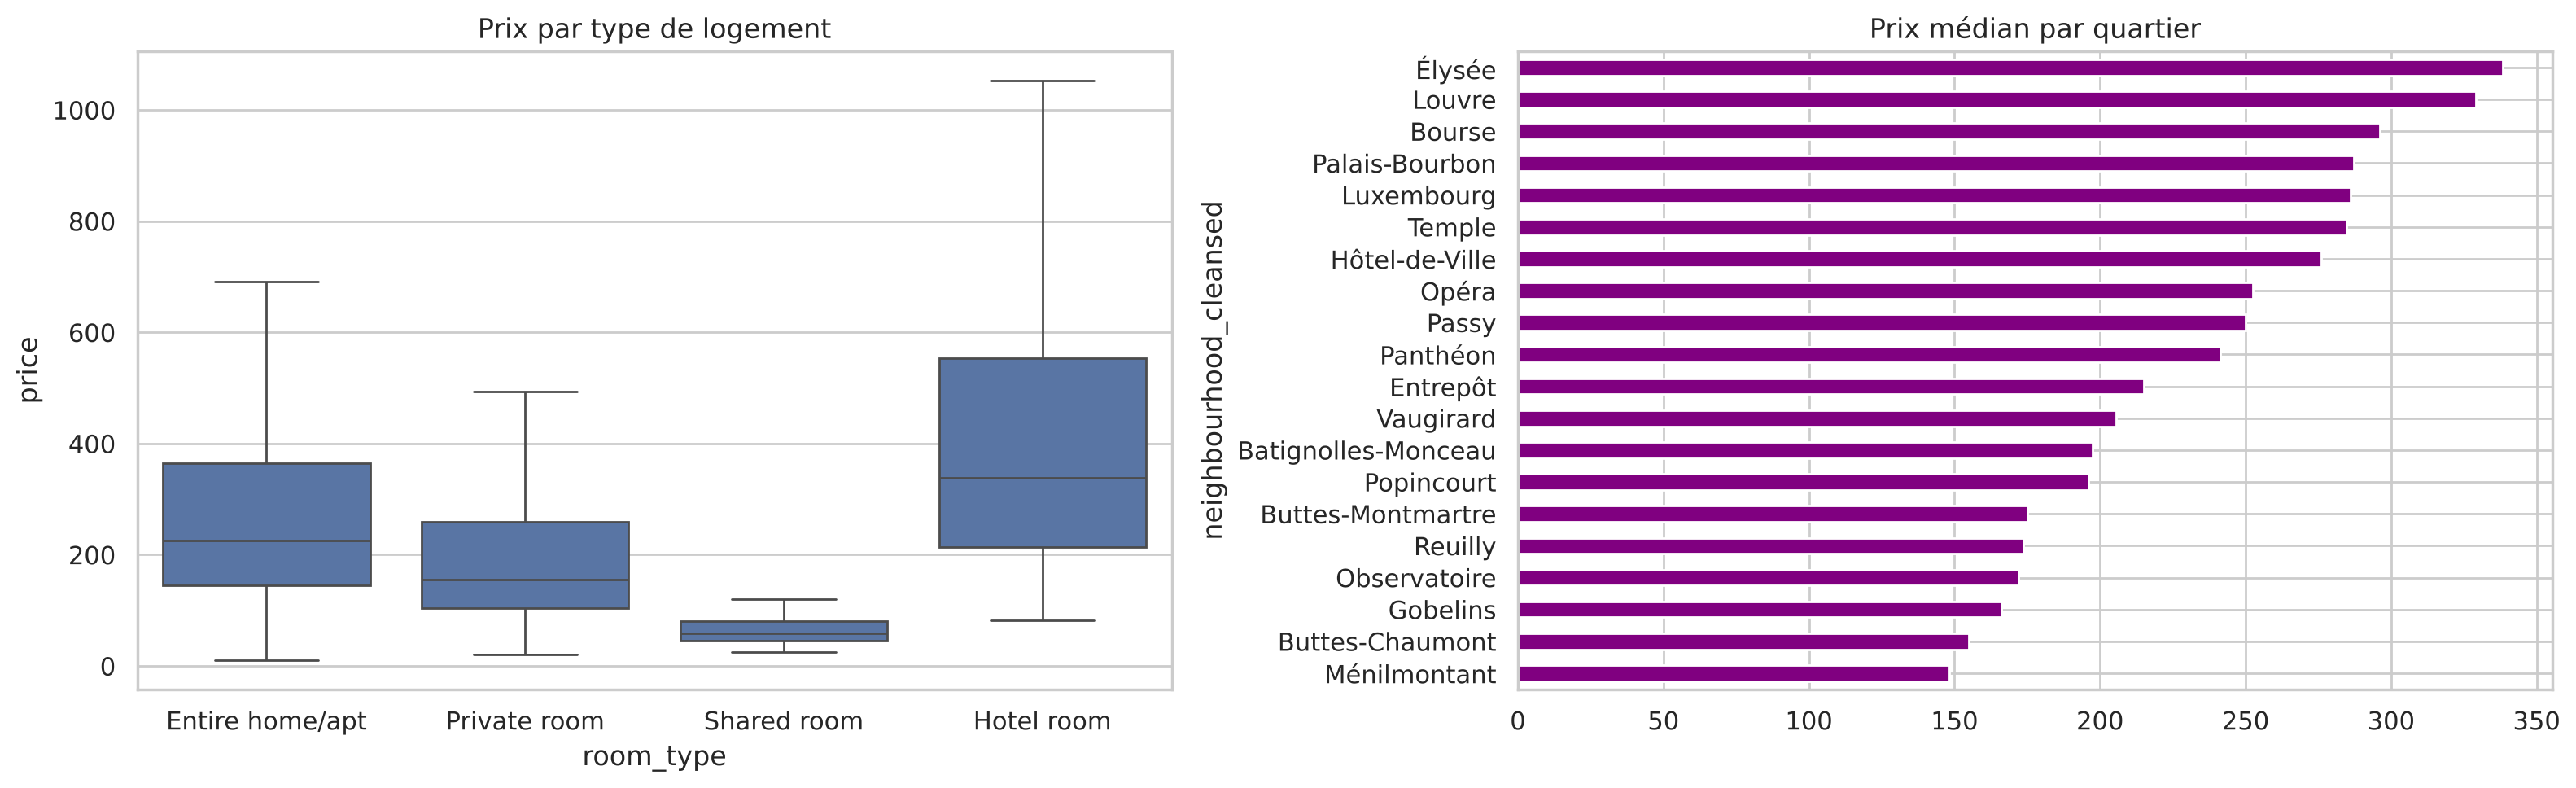

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=df, x='room_type', y='price', ax=ax[0], showfliers=False)
ax[0].set_title('Prix par type de logement')

df.groupby('neighbourhood_cleansed')['price'].median().sort_values().plot(kind='barh', ax=ax[1], color='purple')
ax[1].set_title('Prix médian par quartier')

plt.tight_layout()
plt.show()

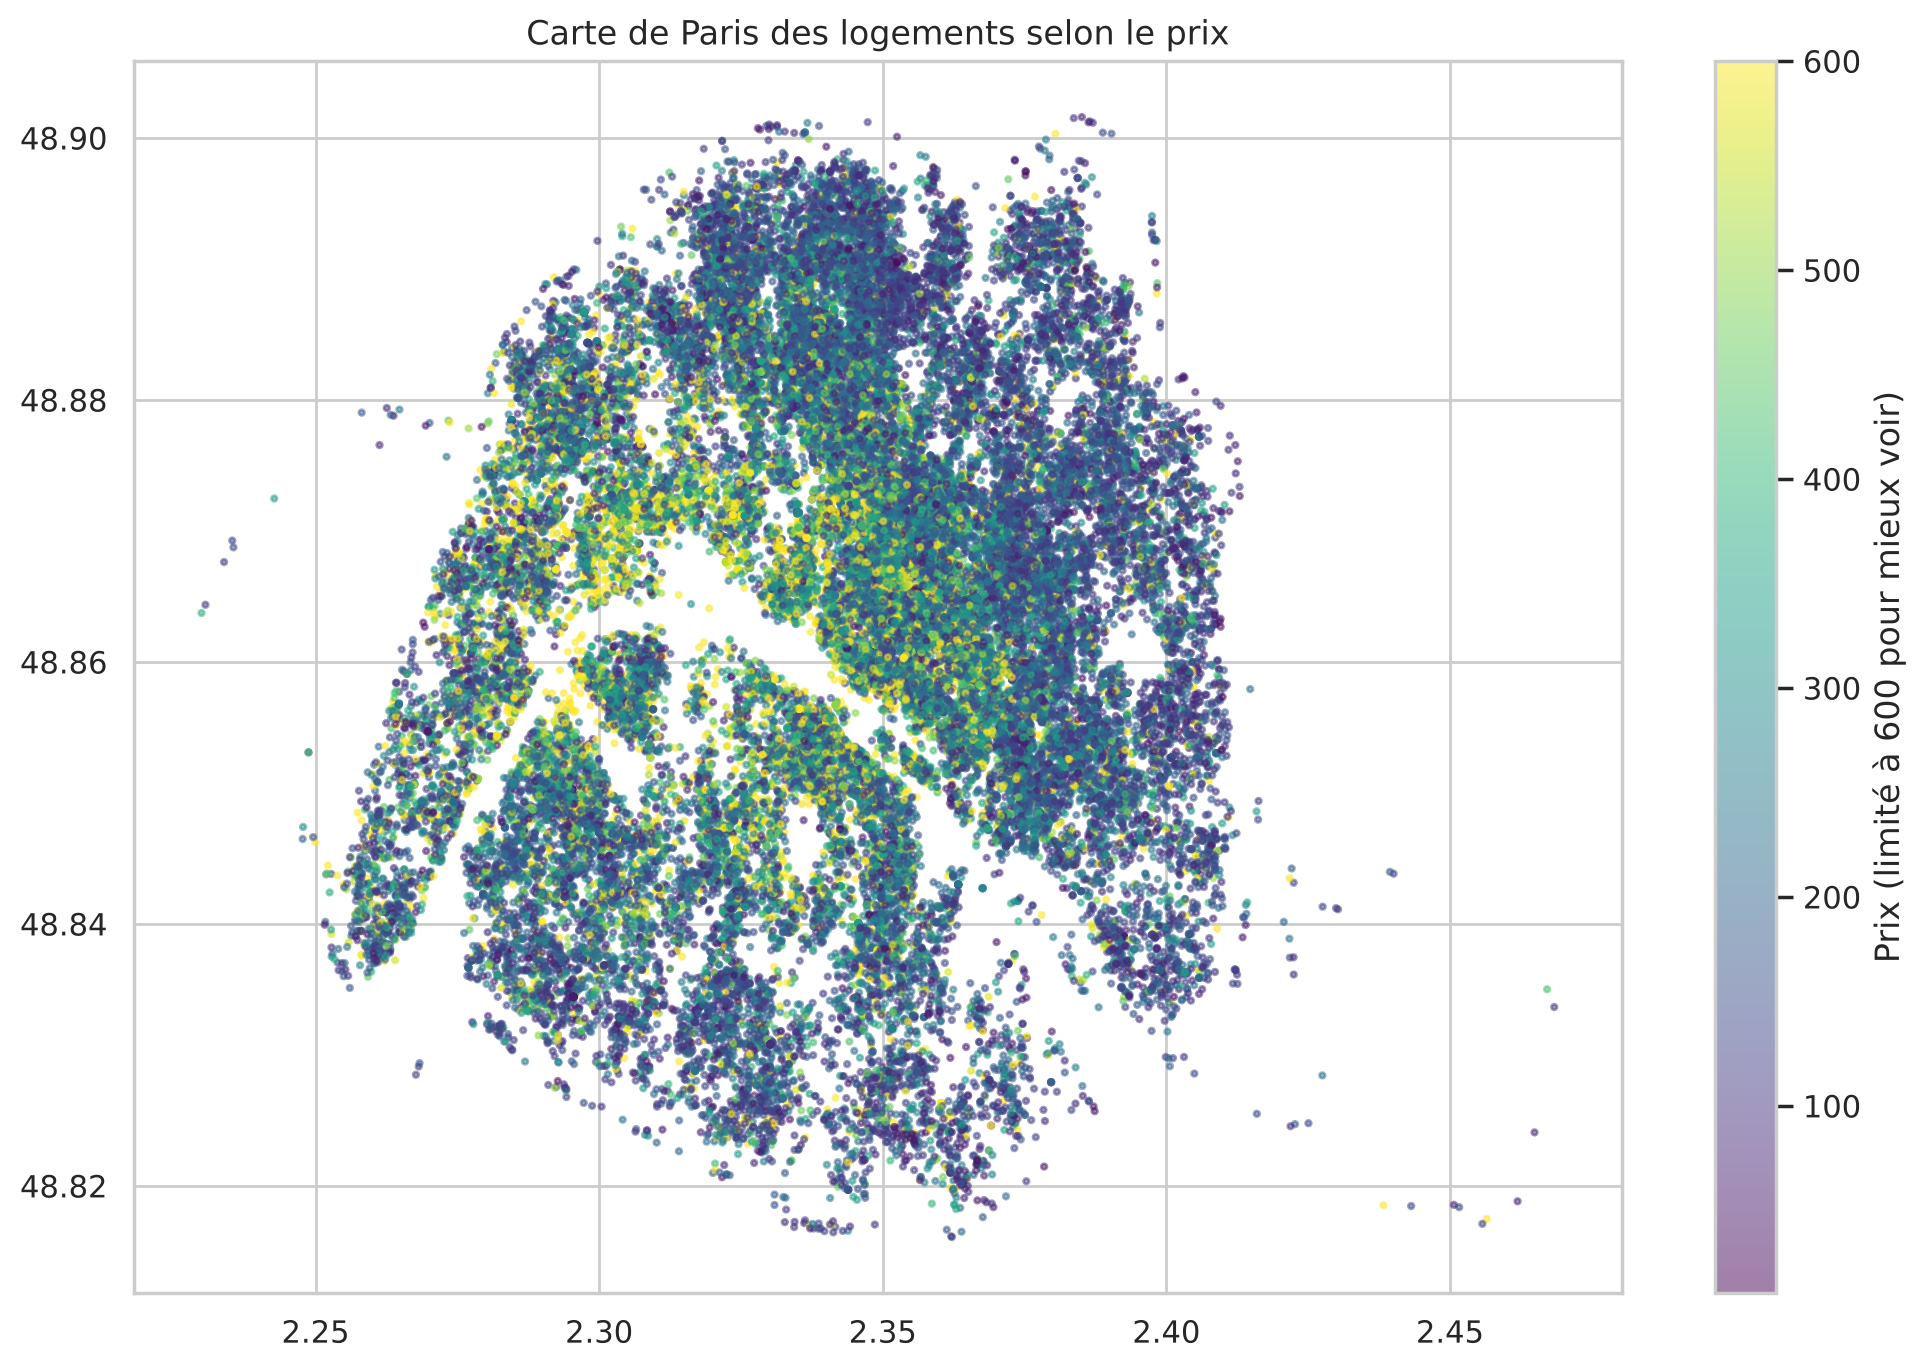

In [10]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(df['longitude'], df['latitude'], c=df['price'].clip(upper=600), cmap='viridis', s=4, alpha=0.5)
plt.colorbar(scatter, label='Prix (limité à 600 pour mieux voir)')
plt.title('Carte de Paris des logements selon le prix')
plt.show()

Comme dans la première EDA, les prix les plus élevés sont au centre et à l'ouest de Paris.

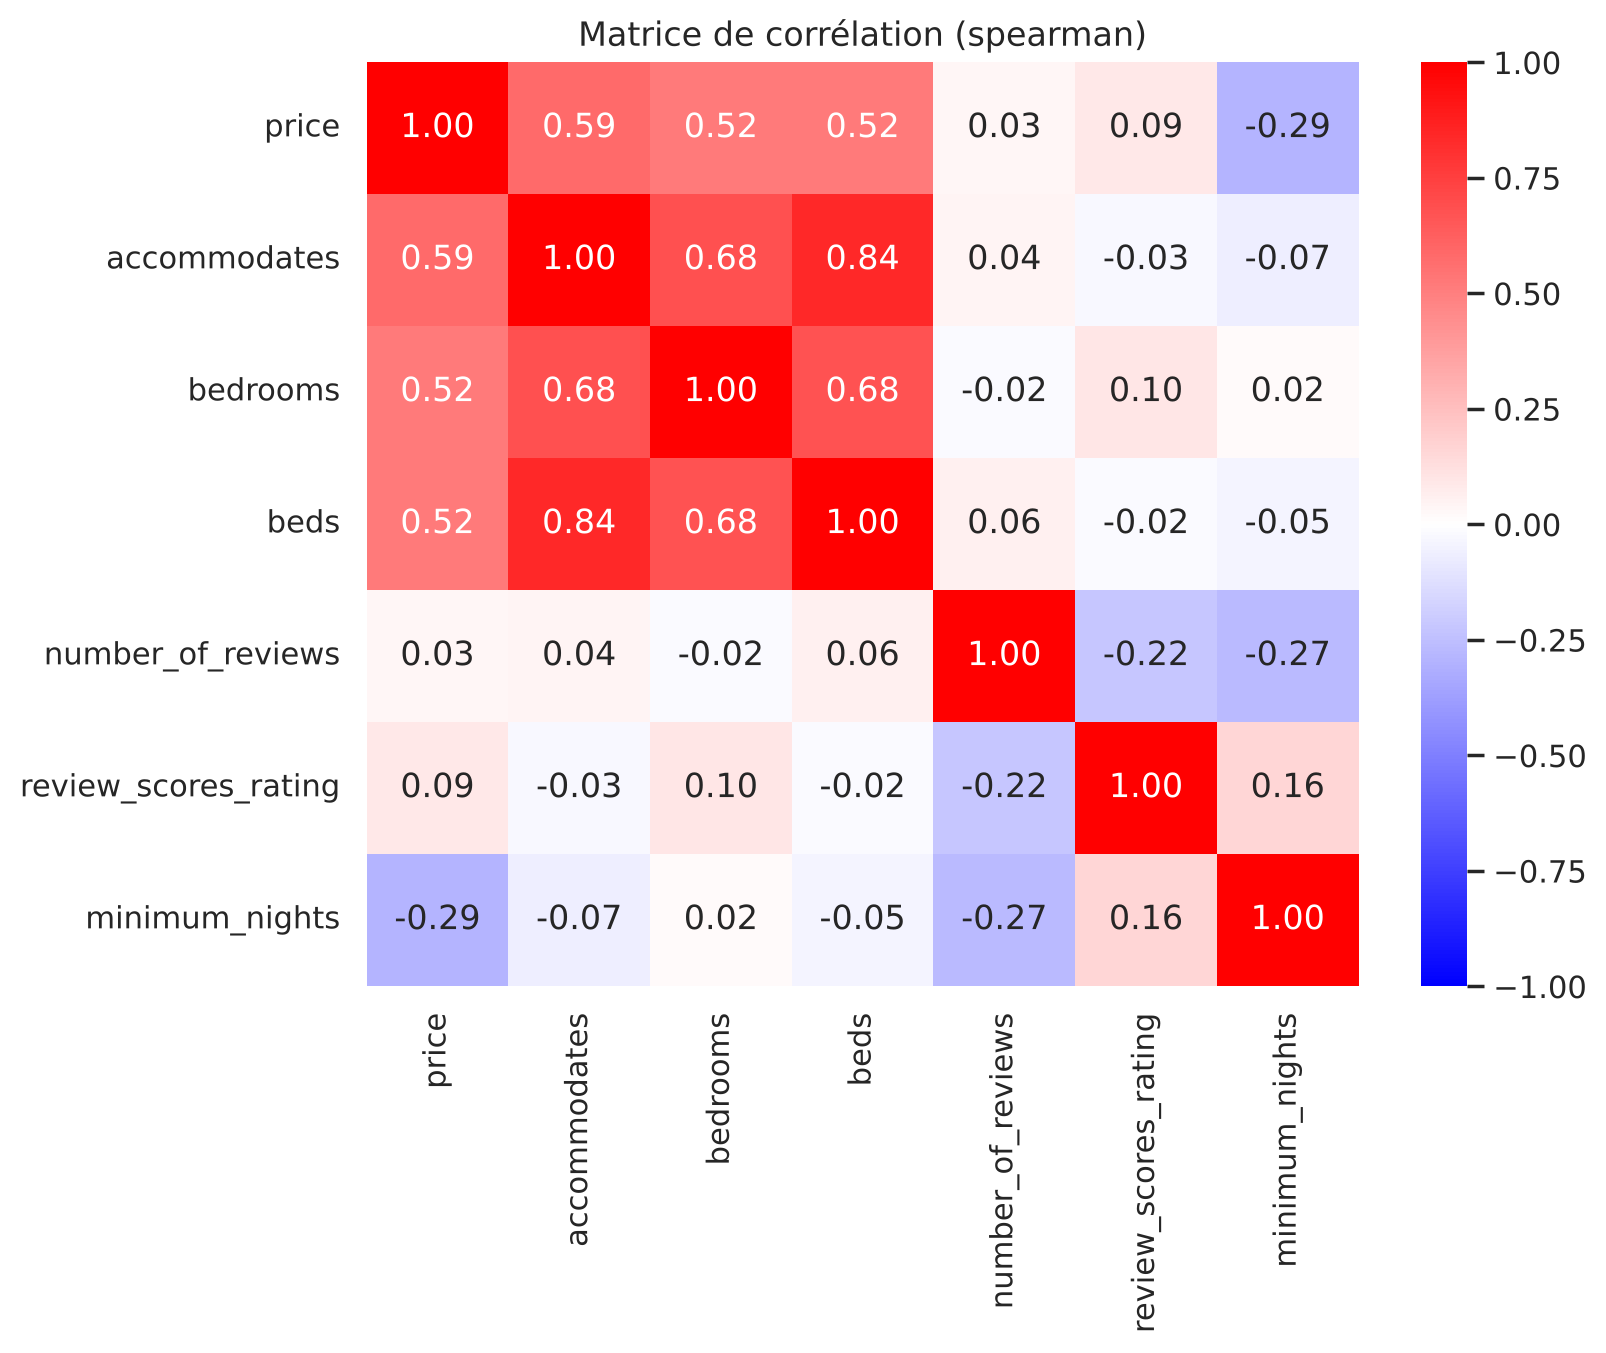

In [11]:
cols = ['price', 'accommodates', 'bedrooms', 'beds', 'number_of_reviews', 'review_scores_rating', 'minimum_nights']

plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='bwr', vmin=-1, vmax=1)
plt.title('Matrice de corrélation (spearman)')
plt.show()

On utilise spearman car le prix est très asymétrique. accommodates et bedrooms sont les plus corrélées avec le prix.

On regarde aussi le prix selon le nombre minimum de nuits :

In [12]:
tranches = pd.cut(df['minimum_nights'], [0, 1, 2, 3, 6, 29, 89, 10000],
                  labels=['1', '2', '3', '4-6', '7-29', '30-89', '90+'])
df.groupby(tranches)['price'].agg(['count', 'median'])

,count,median
minimum_nights,,
1,15883,247.930
2,9983,230.290
3,5683,230.000
4-6,4341,240.830
7-29,1376,197.665
30-89,5230,91.140
90+,539,90.740


Les logements avec 30 nuits minimum ou plus ont un prix médian autour de 90 € contre environ 230-250 € pour les autres. Ce sont des locations moyenne durée (par exemple Blueground), pas des locations touristiques.

Pour les notes, les logements sans note sont ceux qui n'ont aucun avis :

In [13]:
sans_note = df['review_scores_rating'].isna()
print("Logements sans note :", sans_note.sum())
print(df[sans_note]['number_of_reviews'].value_counts())

Logements sans note : 7202
number_of_reviews
0    7202
Name: count, dtype: int64


## Feature engineering

### Taux d'occupation

On utilise le calendrier pour calculer la part des jours où le logement n'est pas disponible. Attention ce n'est pas un vrai taux d'occupation car un jour non disponible peut aussi être bloqué par l'hôte.

In [14]:
df_cal = pd.read_parquet(chemin_airbnb / "calendar.parquet", columns=['listing_id', 'available'])
df_cal['pas_dispo'] = (df_cal['available'] == 'f').astype(int)

taux = df_cal.groupby('listing_id')['pas_dispo'].mean().rename('taux_occupation')
del df_cal

df = df.merge(taux, left_on='id', right_index=True, how='left')
df['taux_occupation'].describe()

count    43151.000000
mean         0.426179
std          0.316902
min          0.000000
25%          0.136986
50%          0.336986
75%          0.726027
max          0.997260
Name: taux_occupation, dtype: float64

### Distance aux transports

Avant, la distance était calculée avec un cKDTree sur la latitude et la longitude en radians. Le problème c'est qu'à Paris un degré de longitude est plus petit qu'un degré de latitude (environ 0.66 fois), donc les distances étaient fausses. On utilise un BallTree avec la distance haversine qui calcule la vraie distance sur la Terre.

On fait aussi deux variables car le fichier contient toutes les gares d'Ile-de-France et pas seulement le métro.

In [15]:
stations = pd.read_parquet(chemin_poi / "train_station_scnf.parquet")
coords = stations['Geo Point'].str.split(',', expand=True).astype(float)
stations['lat'] = coords[0]
stations['lon'] = coords[1]

print(stations['mode_'].value_counts().head(8))

mode_
METRO           277
TRAIN           221
TRAM            217
RER             171
TRAIN / RER      28
METRO / TRAM     26
RER / TRAM       17
RER / METRO      11
Name: count, dtype: int64


In [16]:
def distance_plus_proche(points, references):
    # distance en mètres entre chaque point et la référence la plus proche
    arbre = BallTree(np.radians(references), metric='haversine')
    distances, _ = arbre.query(np.radians(points), k=1)
    return distances[:, 0] * 6371000

points = df[['latitude', 'longitude']].values
metros = stations[stations['metro'] == 1][['lat', 'lon']].values
toutes_gares = stations[['lat', 'lon']].values

df['dist_metro_m'] = distance_plus_proche(points, metros).round(1)
df['dist_station_m'] = distance_plus_proche(points, toutes_gares).round(1)

On compare avec l'ancienne méthode :

In [17]:
arbre = cKDTree(np.radians(toutes_gares))
dist_ancienne, _ = arbre.query(np.radians(points), k=1)
dist_ancienne = dist_ancienne * 6371000

ecart = dist_ancienne / df['dist_station_m'] - 1
print("Ecart moyen :", round(ecart.mean() * 100, 1), "%")
print("Ecart max :", round(ecart.max() * 100, 1), "%")

Ecart moyen : 24.3 %
Ecart max : 52.4 %


L'ancienne méthode surestimait les distances de 24 % en moyenne et jusqu'à 52 % quand la gare est à l'est ou à l'ouest du logement.

### Distance au centre

Vu que les prix baissent quand on s'éloigne du centre, on ajoute la distance au point zéro de Paris (devant Notre-Dame).

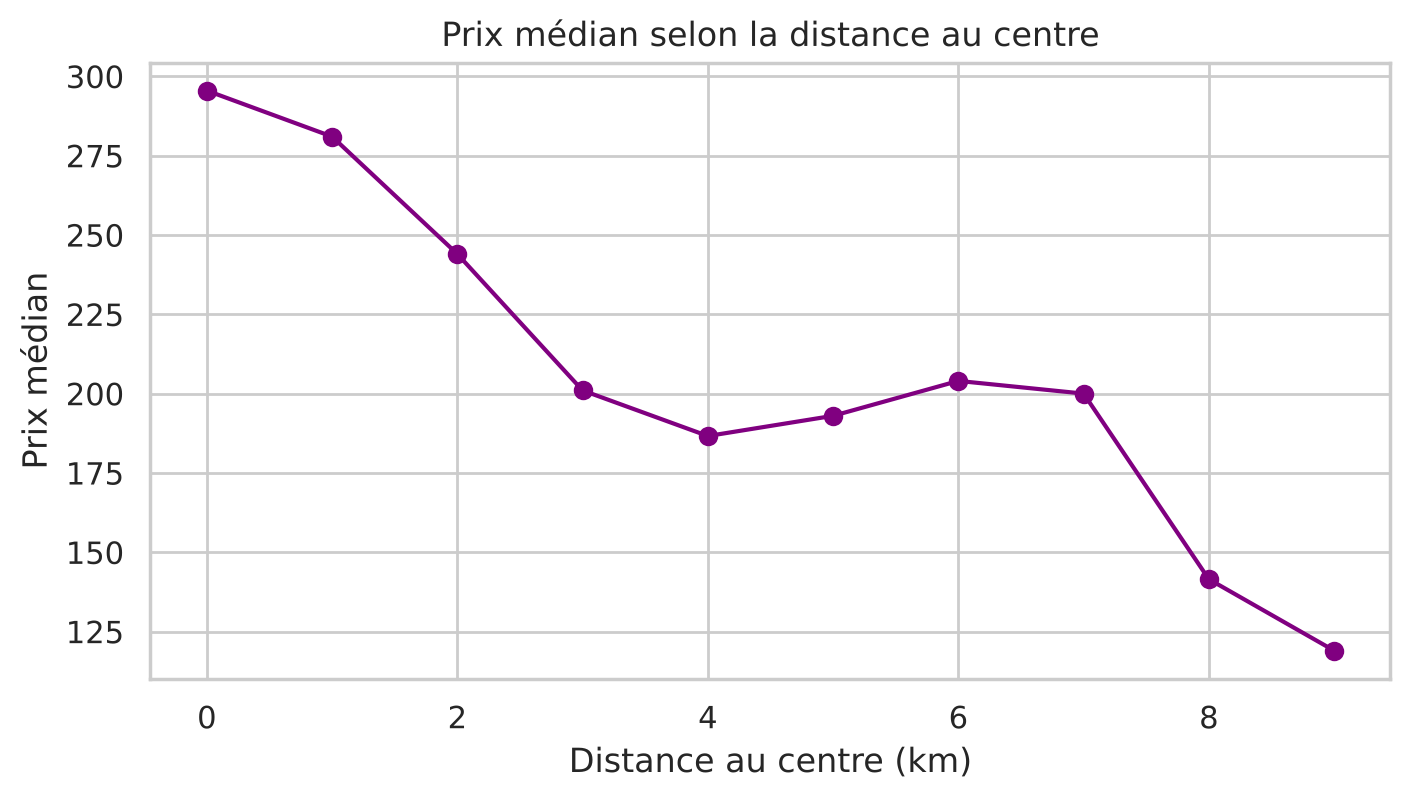

In [18]:
centre = np.array([[48.85341, 2.34880]])
df['dist_centre_m'] = distance_plus_proche(points, centre).round(1)

# prix médian par km de distance au centre
km = (df['dist_centre_m'] / 1000).round(0)
df.groupby(km)['price'].median().plot(marker='o', color='purple', figsize=(8, 4))
plt.xlabel('Distance au centre (km)')
plt.ylabel('Prix médian')
plt.title('Prix médian selon la distance au centre')
plt.show()

### Variables de l'hôte

In [19]:
df['host_is_superhost'] = df['host_is_superhost'].map({'t': 1, 'f': 0})
df['host_identity_verified'] = df['host_identity_verified'].map({'t': 1, 'f': 0})

### Nouvelles variables

On avait laissé de côté plusieurs colonnes qui peuvent aider.

Les salles de bain sont dans bathrooms_text sous forme de texte ("1 bath", "1.5 baths", "1 shared bath"...). On récupère le nombre et si la salle de bain est partagée.

In [20]:
sdb = df['bathrooms_text'].fillna('').str.lower()
df['nb_sdb'] = pd.to_numeric(sdb.str.extract(r'(\d+\.?\d*)')[0], errors='coerce')
# "half-bath" n'a pas de chiffre
df.loc[sdb.str.contains('half') & df['nb_sdb'].isna(), 'nb_sdb'] = 0.5
df['sdb_partagee'] = sdb.str.contains('shared').astype(int)

df.groupby('nb_sdb')['price'].agg(['count', 'median']).head(8)

,count,median
nb_sdb,,
0.0,285,181.06
0.5,303,94.50
1.0,33521,193.00
1.5,3330,246.50
2.0,3708,473.92
2.5,928,548.50
3.0,664,684.25
3.5,151,884.00


Dans l'analyse des erreurs on a vu qu'il manquait la surface. Elle n'est pas dans les colonnes mais beaucoup d'hôtes l'écrivent dans le titre ou la description ("studio (18m2)", "65 square meters"...). On la récupère avec une regex.

In [21]:
df['texte'] = (df['name'].fillna('') + ' . ' + df['description'].fillna('')).str.lower()

surface = df['texte'].str.extract(r'(\d{2,3}[.,]?\d?)\s?(?:m²|m2|sqm|sq m|square met|mètres carrés|metres carres)')[0]
surface = pd.to_numeric(surface.str.replace(',', '.'), errors='coerce')

# on garde seulement les valeurs possibles
df['surface_m2'] = surface.where(surface.between(9, 500))

print("Logements avec une surface :", round(df['surface_m2'].notna().mean() * 100, 1), "%")
print("Corrélation surface / prix :", round(df[['surface_m2', 'price']].corr(method='spearman').iloc[0, 1], 2))

Logements avec une surface : 30.6 %
Corrélation surface / prix : 0.59


On trouve la surface pour environ 30 % des logements. Pour les autres ça reste NaN, HistGradientBoosting sait gérer les valeurs manquantes.

On ajoute aussi l'ancienneté de l'annonce (nombre de jours depuis le premier avis).

In [22]:
date_donnees = pd.Timestamp('2026-09-16')
df['anciennete_jours'] = (date_donnees - pd.to_datetime(df['first_review'])).dt.days
df['anciennete_jours'].describe()

count    35949.000000
mean      1279.044841
std       1209.364976
min         -6.000000
25%        422.000000
50%        873.000000
75%       1613.000000
max       6077.000000
Name: anciennete_jours, dtype: float64

## Transformateurs

On reprend les transformateurs du projet avec quelques changements :
- NettoyeurMaximumNights : on limite maximum_nights et minimum_nights à 365 (il y avait des valeurs à 2 milliards qui faisaient planter la Ridge).
- ExtracteurAmenities : on lit la liste avec json.loads, on prend les 30 équipements les plus fréquents et on ajoute le nombre d'équipements.
- ImputerAvisAirbnb : pareil qu'avant, la médiane des notes et la variable a_des_avis.
- ImputerCapacite : on remplace les beds et maintenant aussi les bedrooms par la médiane selon accommodates.

Les médianes sont calculées dans le fit donc seulement sur le train.

In [23]:
class NettoyeurMaximumNights(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X['maximum_nights'] = X['maximum_nights'].clip(upper=365)
        X['minimum_nights'] = X['minimum_nights'].clip(upper=365)
        return X


class ExtracteurAmenities(BaseEstimator, TransformerMixin):
    def __init__(self, top_n=30):
        self.top_n = top_n

    def convertir_en_liste(self, x):
        if pd.isna(x):
            return []
        return json.loads(x)

    def fit(self, X, y=None):
        listes = X['amenities'].apply(self.convertir_en_liste)
        compte = listes.explode().value_counts()
        self.top_amenities_ = compte.head(self.top_n).index.tolist()
        return self

    def transform(self, X):
        X = X.copy()
        listes = X['amenities'].apply(self.convertir_en_liste)
        X['nb_equipements'] = listes.apply(len)

        for am in self.top_amenities_:
            nom = 'amenity_' + am.lower().replace(' ', '_').replace('/', '_')
            X[nom] = listes.apply(lambda liste: 1 if am in liste else 0)

        return X.drop(columns=['amenities'])


class ImputerAvisAirbnb(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.colonnes_scores_ = [c for c in X.columns if 'review_scores_' in c]
        self.medianes_ = X[self.colonnes_scores_].median()
        return self

    def transform(self, X):
        X = X.copy()
        X['a_des_avis'] = (X['number_of_reviews'] > 0).astype(int)
        X['reviews_per_month'] = X['reviews_per_month'].fillna(0)
        X[self.colonnes_scores_] = X[self.colonnes_scores_].fillna(self.medianes_)
        return X


class ImputerCapacite(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.lits_ = X.groupby('accommodates')['beds'].median()
        self.chambres_ = X.groupby('accommodates')['bedrooms'].median()
        return self

    def transform(self, X):
        X = X.copy()
        # médiane selon la capacité, et 1 si la capacité n'a pas été vue dans le train
        X['beds'] = X['beds'].fillna(X['accommodates'].map(self.lits_)).fillna(1)
        X['bedrooms'] = X['bedrooms'].fillna(X['accommodates'].map(self.chambres_)).fillna(1)
        return X

## Train / test

In [24]:
colonnes_numeriques = [
    'accommodates', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights',
    'host_is_superhost', 'host_identity_verified', 'host_listings_count', 'hosts_time_as_host_years',
    'number_of_reviews', 'number_of_reviews_ltm', 'reviews_per_month',
    'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness',
    'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value',
    'availability_30', 'availability_60', 'availability_90', 'availability_365',
    'taux_occupation', 'dist_metro_m', 'dist_station_m', 'dist_centre_m', 'latitude', 'longitude',
    'nb_sdb', 'sdb_partagee', 'surface_m2', 'anciennete_jours', 'estimated_occupancy_l365d',
    'minimum_nights_avg_ntm', 'calculated_host_listings_count_entire_homes', 'number_of_reviews_l30d'
]
colonnes_categorielles = ['room_type', 'property_type', 'neighbourhood_cleansed']

X = df[colonnes_numeriques + colonnes_categorielles + ['amenities']]
y = np.log1p(df['price'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train :", X_train.shape, "Test :", X_test.shape)

Train : (34520, 41) Test : (8631, 41)


### Le texte des annonces

Le titre et la description contiennent des infos que les autres colonnes n'ont pas ("vue tour Eiffel", "luxueux", "terrasse", "rénové"...). On transforme le texte avec un TF-IDF et on entraîne une Ridge dessus pour prédire le prix. La prédiction de cette Ridge devient une nouvelle variable prix_texte pour le modèle final.

Pour ne pas tricher, sur le train on utilise cross_val_predict : chaque logement reçoit une prédiction faite par une Ridge qui ne l'a pas vu. Pour le test on utilise une Ridge entraînée sur tout le train.

In [25]:
tfidf = TfidfVectorizer(min_df=5, max_features=30000, ngram_range=(1, 2), sublinear_tf=True)
texte_train = tfidf.fit_transform(df.loc[X_train.index, 'texte'])
texte_test = tfidf.transform(df.loc[X_test.index, 'texte'])

ridge_texte = Ridge(alpha=3)

# train : prédictions faites sans voir le logement
X_train = X_train.copy()
X_train['prix_texte'] = cross_val_predict(ridge_texte, texte_train, y_train, cv=KFold(5, shuffle=True, random_state=0))

# test : ridge entrainée sur tout le train
ridge_texte.fit(texte_train, y_train)
X_test = X_test.copy()
X_test['prix_texte'] = ridge_texte.predict(texte_test)

colonnes_numeriques.append('prix_texte')

print("R2 de la Ridge sur le texte seul (test) :", round(r2_score(y_test, X_test['prix_texte']), 3))

R2 de la Ridge sur le texte seul (test) : 0.489


Les mots qui font le plus monter ou baisser le prix d'après la Ridge :

In [26]:
coefs = pd.Series(ridge_texte.coef_, index=tfidf.get_feature_names_out()).sort_values()
print("Font baisser le prix :", list(coefs.head(15).index))
print()
print("Font monter le prix :", list(coefs.tail(15).index[::-1]))

Font baisser le prix : ['studio', 'chambre', 'shared', 'bail', 'lease', 'room in', 'mobilité', 'bm', 'private room', 'mobility lease', 'mobility', 'room', 'studette', 'bail mobilité', 'months']

Font monter le prix : ['bedrooms', 'luxury', 'family', 'bathrooms', 'luxurious', 'olympics', 'olympic', 'ac', '3br', 'suites', 'chambres', 'penthouse', 'highstay', 'exceptional', 'loft']


Les mots qui font baisser le prix sont logiques : studio, chambre, shared, et tout ce qui parle du bail mobilité (location moyenne durée). Ceux qui font monter le prix parlent de grands logements (bedrooms, 3br, family) ou de luxe (luxury, penthouse, exceptional). On voit aussi "olympics", des annonces qui ont gardé leur texte des JO 2024.

La Ridge sur le texte seul a un R2 de 0.49, ce n'est pas suffisant tout seul mais ça complète bien les autres variables.

## Pipeline

- les transformateurs du dessus
- pour les numériques : médiane pour les NaN et RobustScaler
- pour les catégorielles : one hot encoding, les modalités qui apparaissent moins de 30 fois sont regroupées
- les colonnes amenities sont déjà en 0/1 donc on les laisse comme ça

In [27]:
def creer_pipeline(regresseur):
    nettoyage = Pipeline(steps=[
        ('nettoyage_nuits', NettoyeurMaximumNights()),
        ('amenities', ExtracteurAmenities(top_n=30)),
        ('reviews', ImputerAvisAirbnb()),
        ('capacite', ImputerCapacite())
    ])

    numerical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('ohe', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ('numeric', numerical_transformer, colonnes_numeriques + ['nb_equipements']),
        ('cat', categorical_transformer, colonnes_categorielles)
    ], remainder='passthrough')

    return Pipeline(steps=[
        ('custom', nettoyage),
        ('preprocessor', preprocessor),
        ('regressor', regresseur)
    ])

## Modèles

On compare Ridge, Random Forest et HistGradientBoosting avec un GridSearch (cv=3). Pour la Random Forest on teste min_samples_leaf car dans la première version elle sur-apprenait beaucoup (R2 train 0.95 et test 0.72).

In [28]:
regressors = [
    ('Ridge', Ridge()),
    ('Random Forest', RandomForestRegressor(n_estimators=150, max_features=0.5, random_state=42, n_jobs=-1)),
    ('HistGradientBoosting', HistGradientBoostingRegressor(max_iter=1500, learning_rate=0.03, max_leaf_nodes=63, random_state=42))
]

params_grid = {
    'Ridge': {'regressor__alpha': [0.1, 1, 10, 100]},
    'Random Forest': {'regressor__min_samples_leaf': [1, 3, 8]},
    'HistGradientBoosting': {
        'regressor__max_features': [0.5, 1.0],
        'regressor__l2_regularization': [1, 5]
    }
}

In [29]:
results = {}
modeles_entraines = {}

y_test_euros = np.expm1(y_test)
# pour comparer avec l'ancienne version qui n'avait que des prix < 1000
moins_de_1000 = y_test_euros < 1000

for nom, regresseur in regressors:
    print("Entrainement :", nom)
    model = GridSearchCV(creer_pipeline(regresseur), params_grid[nom], cv=3, scoring='r2', n_jobs=-1)
    model.fit(X_train, y_train)

    y_pred_log = model.predict(X_test)
    y_pred_euros = np.expm1(y_pred_log)
    modeles_entraines[nom] = model.best_estimator_

    results[nom] = {
        'Best params': model.best_params_,
        'R2 train': round(r2_score(y_train, model.best_estimator_.predict(X_train)), 3),
        'R2 CV': round(model.best_score_, 3),
        'R2 test': round(r2_score(y_test, y_pred_log), 3),
        'MAE (€)': round(mean_absolute_error(y_test_euros, y_pred_euros), 2),
        'Erreur médiane (€)': round(median_absolute_error(y_test_euros, y_pred_euros), 2),
        'MAE prix < 1000 (€)': round(mean_absolute_error(y_test_euros[moins_de_1000], y_pred_euros[moins_de_1000]), 2)
    }

df_results = pd.DataFrame(results).T
df_results

Entrainement : Ridge


Entrainement : Random Forest


Entrainement : HistGradientBoosting


,Best params,R2 train,R2 CV,R2 test,MAE (€),Erreur médiane (€),MAE prix < 1000 (€)
Ridge,{'regressor__alpha': 10},0.683,0.679,0.684,89.21,48.32,75.53
Random Forest,{'regressor__min_samples_leaf': 1},0.971,0.783,0.79,75.41,37.69,62.32
HistGradientBoosting,"{'regressor__l2_regularization': 5, 'regressor...",0.886,0.811,0.821,68.99,34.72,57.59


HistGradientBoosting est encore le meilleur modèle.

Pour la Random Forest le GridSearch a gardé min_samples_leaf=1 donc elle sur-apprend toujours (R2 train 0.97), mais son R2 test passe quand même de 0.72 à 0.79 avec max_features=0.5 et les nouvelles variables.

Pour HistGradientBoosting on a baissé le learning_rate (0.03) avec plus d'itérations (1500), et le GridSearch a choisi max_features=0.5 et l2_regularization=5, ce qui limite le sur-apprentissage.

La Ridge est loin derrière, la relation entre les variables et le prix n'est pas linéaire.

Pour comparer avec l'ancienne version (R2 test 0.749 et MAE 66.69 €) il faut regarder la MAE sur les prix < 1000 € car avant le modèle n'avait que ces logements.

In [30]:
nom_meilleur = df_results['MAE (€)'].astype(float).idxmin()
meilleur_modele = modeles_entraines[nom_meilleur]

print("Meilleur modèle :", nom_meilleur)
print("R2 test :", results[nom_meilleur]['R2 test'], "(avant 0.749)")
print("MAE prix < 1000 € :", results[nom_meilleur]['MAE prix < 1000 (€)'], "(avant 66.69)")

Meilleur modèle : HistGradientBoosting
R2 test : 0.821 (avant 0.749)
MAE prix < 1000 € : 57.59 (avant 66.69)


## Analyse des erreurs

On regarde où le modèle se trompe le plus selon la gamme de prix.

In [31]:
y_pred_euros = np.expm1(meilleur_modele.predict(X_test))

erreurs = pd.DataFrame({
    'reel': y_test_euros.values,
    'predit': y_pred_euros,
    'room_type': X_test['room_type'].values
})
erreurs['erreur'] = (erreurs['predit'] - erreurs['reel']).abs()
erreurs['erreur_relative'] = erreurs['erreur'] / erreurs['reel']
erreurs['difference'] = erreurs['predit'] - erreurs['reel']
erreurs['gamme'] = pd.cut(erreurs['reel'], [0, 100, 200, 300, 500, 1000, 2000])

erreurs.groupby('gamme').agg(
    nb=('reel', 'count'),
    MAE=('erreur', 'mean'),
    erreur_relative_mediane=('erreur_relative', 'median'),
    difference_moyenne=('difference', 'mean')
).round(2)

,nb,MAE,erreur_relative_mediane,difference_moyenne
gamme,,,,
"(0, 100]",1089,20.33,0.19,15.24
"(100, 200]",2837,32.22,0.16,16.73
"(200, 300]",1982,49.97,0.16,7.49
"(300, 500]",1578,79.11,0.17,-11.57
"(500, 1000]",910,160.53,0.21,-90.73
"(1000, 2000]",235,476.30,0.34,-463.84


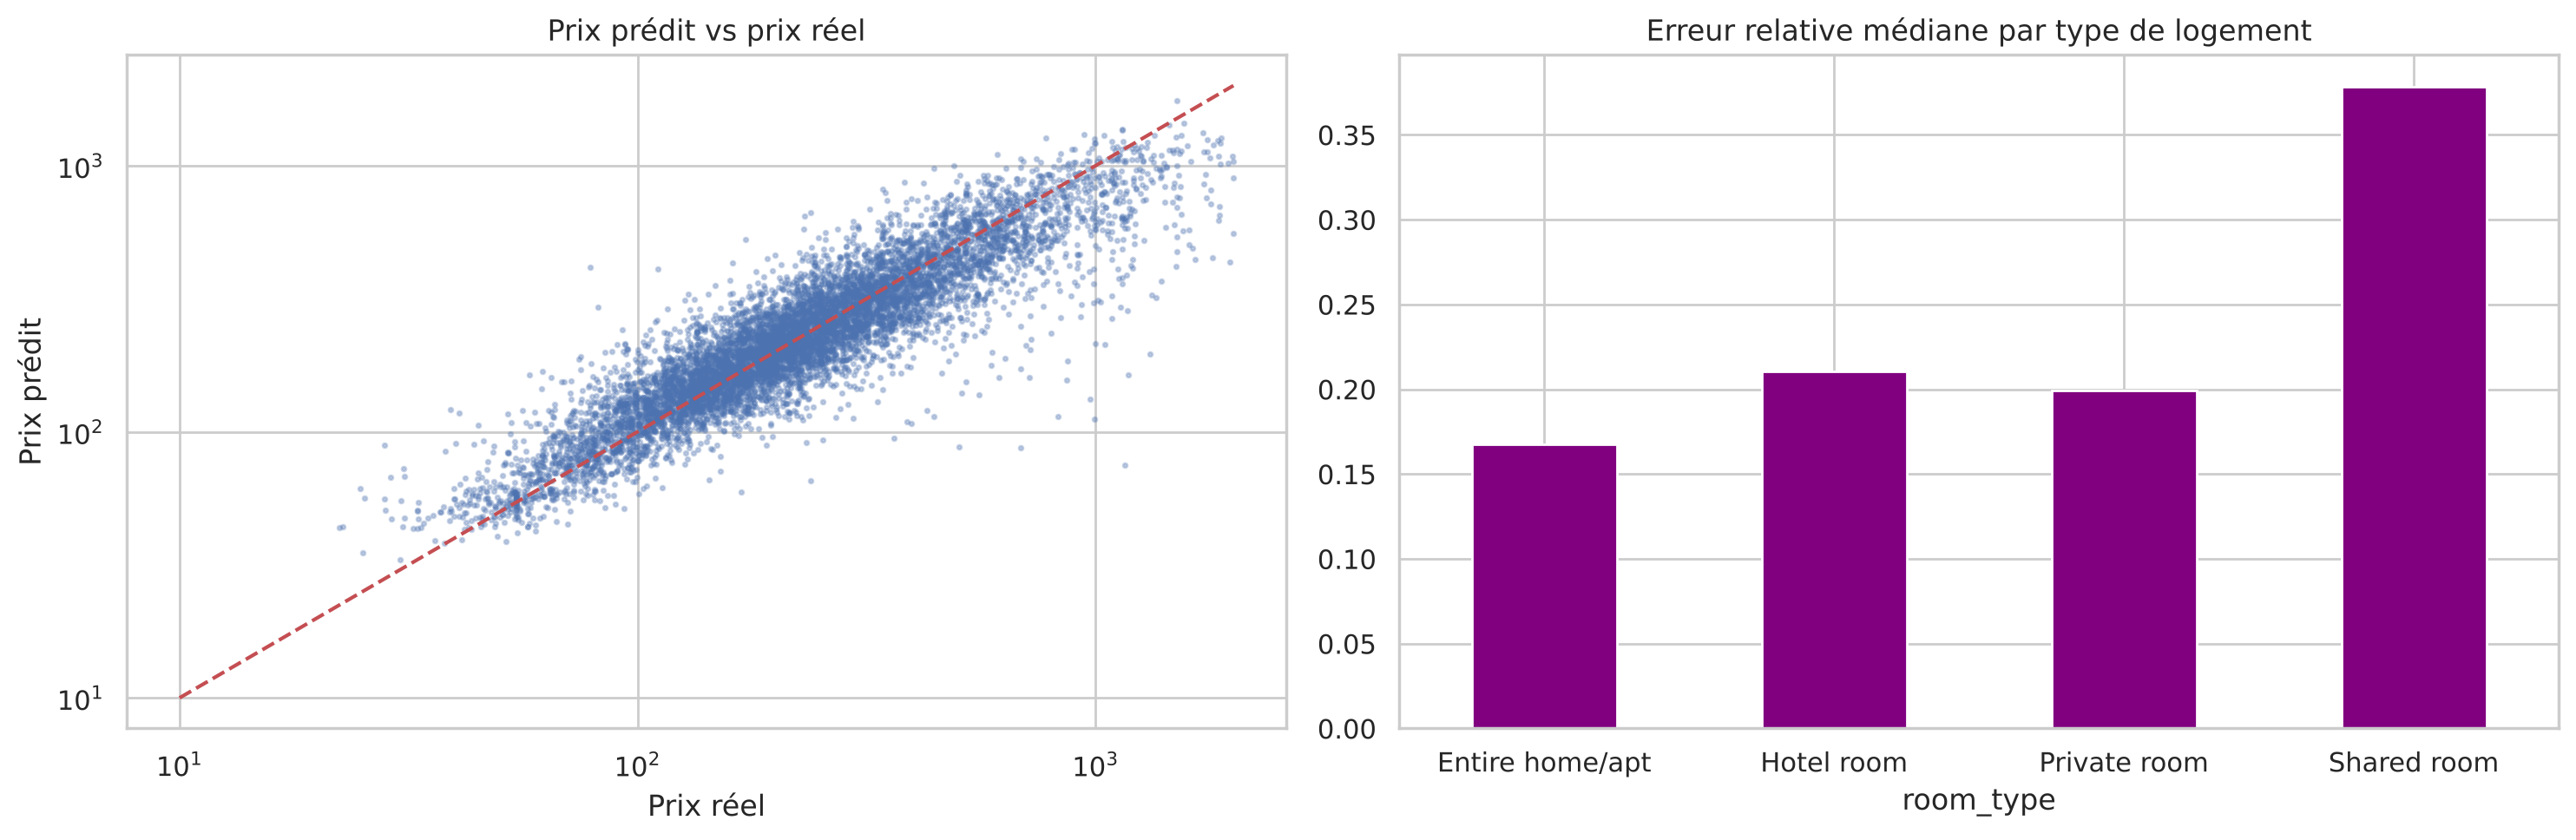

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].scatter(erreurs['reel'], erreurs['predit'], s=3, alpha=0.3)
ax[0].plot([10, 2000], [10, 2000], 'r--')
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel('Prix réel')
ax[0].set_ylabel('Prix prédit')
ax[0].set_title('Prix prédit vs prix réel')

erreurs.groupby('room_type')['erreur_relative'].median().plot(kind='bar', ax=ax[1], color='purple', rot=0)
ax[1].set_title('Erreur relative médiane par type de logement')

plt.tight_layout()
plt.show()

Jusqu'à 1000 € l'erreur relative est assez stable (16 à 21 %), mais en euros elle augmente avec le prix. Au dessus de 1000 € l'erreur relative monte à 34 %, il y a peu de logements de ce type donc le modèle les connaît mal.

La colonne difference_moyenne montre que le modèle surestime les petits prix et sous-estime les gros. Il manque sûrement des infos comme la surface, le standing ou la vue.

Les shared room ont la plus grosse erreur relative mais il y en a très peu.

## Importance des variables

HistGradientBoosting n'a pas de feature_importances_ donc on utilise permutation_importance sur le test.

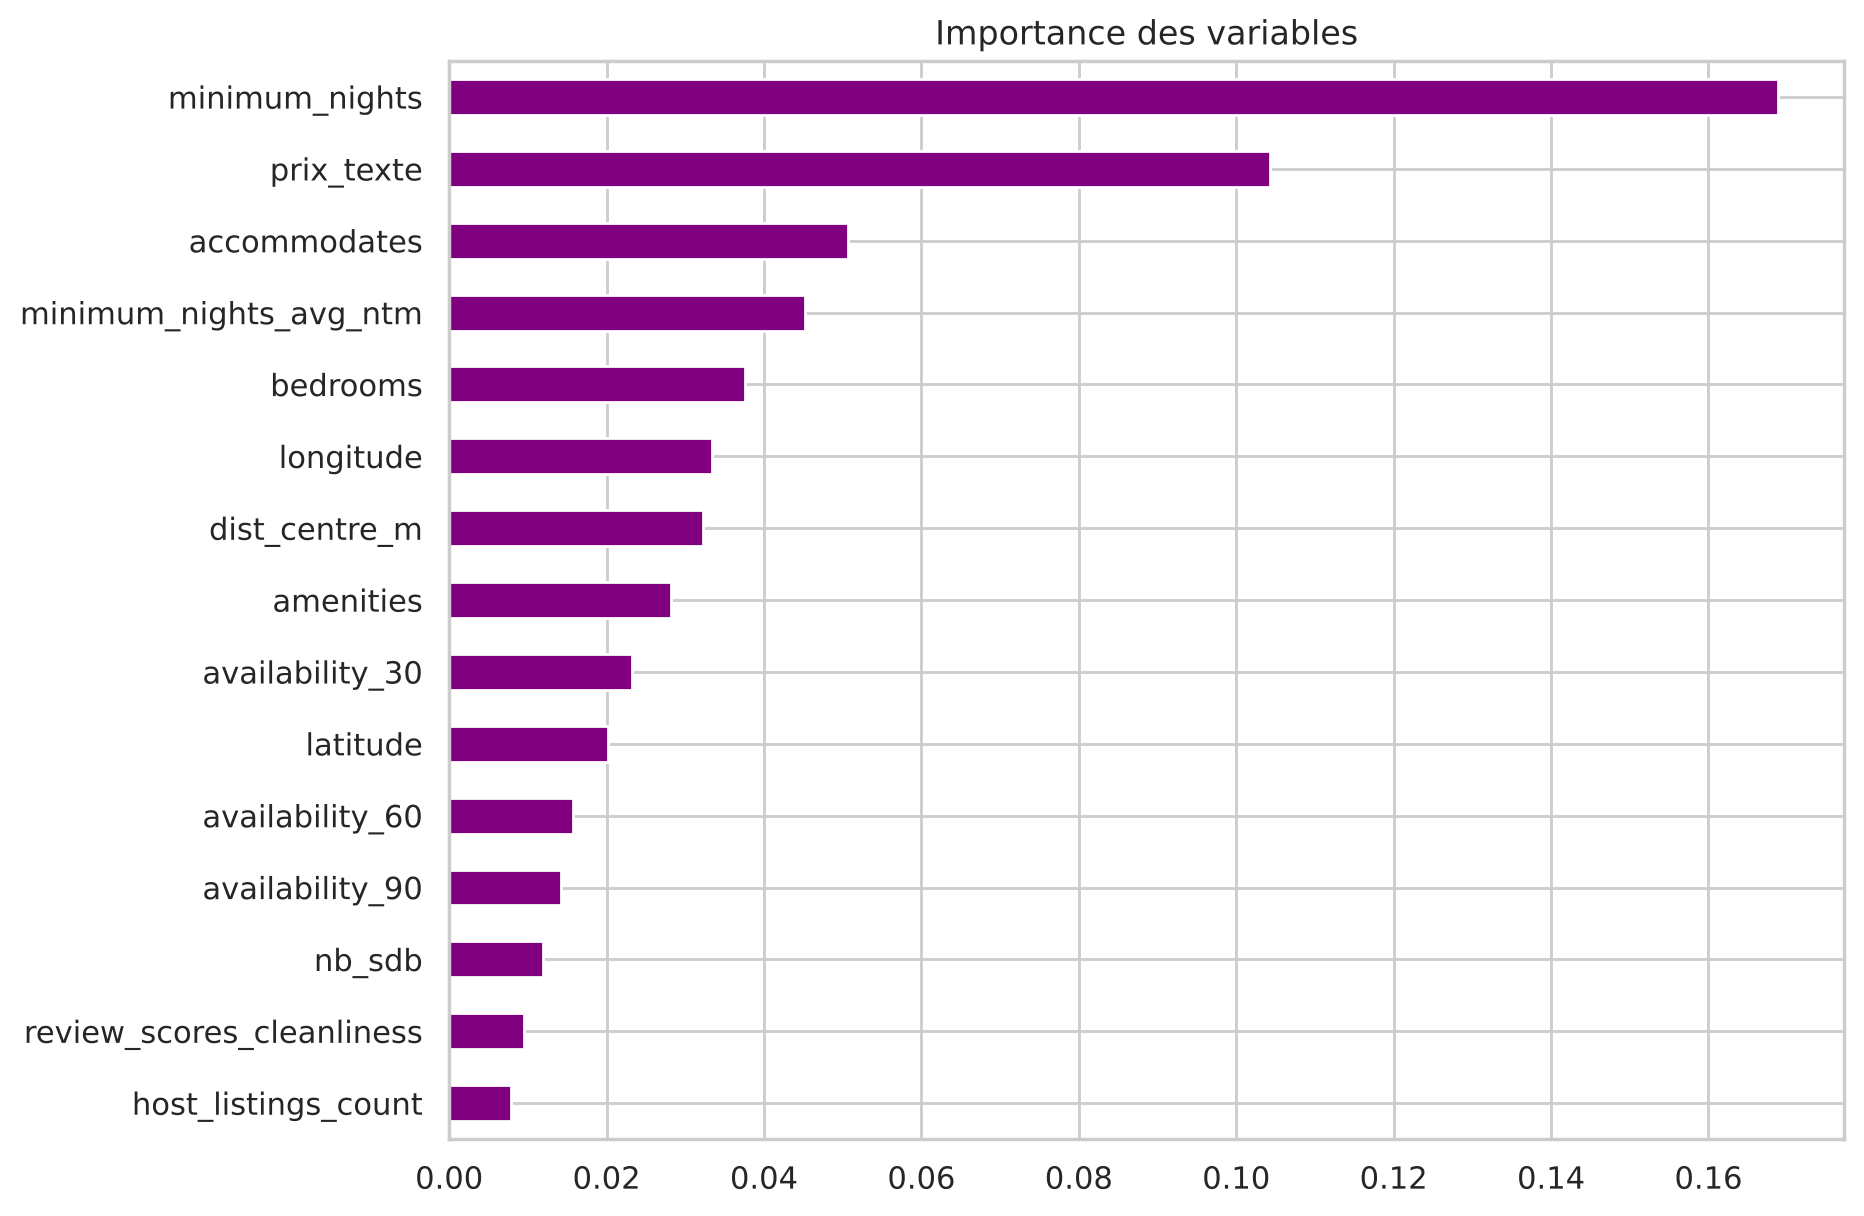

minimum_nights            0.168797
prix_texte                0.104314
accommodates              0.050707
minimum_nights_avg_ntm    0.045263
bedrooms                  0.037604
longitude                 0.033361
dist_centre_m             0.032267
amenities                 0.028180
availability_30           0.023174
latitude                  0.020184
dtype: float64

In [33]:
resultats_importance = permutation_importance(meilleur_modele, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
importances = pd.Series(resultats_importance.importances_mean, index=X_test.columns).sort_values(ascending=False)

importances.head(15).sort_values().plot(kind='barh', color='purple', figsize=(9, 7))
plt.title('Importance des variables')
plt.show()

importances.head(10)

1. minimum_nights reste la variable la plus importante. Comme on l'a vu dans l'EDA, elle sépare la location touristique et la location moyenne durée qui est beaucoup moins chère par nuit. minimum_nights_avg_ntm (la moyenne sur les prochains mois) est aussi dans le top 5.
2. prix_texte, la variable faite avec le texte des annonces, arrive deuxième. Le texte apporte vraiment des infos en plus.
3. accommodates et bedrooms : la taille du logement.
4. longitude, dist_centre_m et latitude : l'emplacement.
5. amenities et les disponibilités ont un impact plus faible.

Les importances des variables de taille et d'emplacement ont baissé par rapport à avant, c'est normal car une partie de l'info est maintenant aussi dans prix_texte (le texte parle souvent du nombre de chambres ou du quartier).

## Sauvegarde du modèle

In [34]:
chemin_modele = chemin_sauvegarde / "modele_airbnb_paris.joblib"
joblib.dump(meilleur_modele, chemin_modele)
print("Modèle sauvegardé dans :", chemin_modele)

# test sur quelques logements
exemple = X_test.head(5)
pd.DataFrame({
    'room_type': exemple['room_type'].values,
    'quartier': exemple['neighbourhood_cleansed'].values,
    'accommodates': exemple['accommodates'].values,
    'prix reel': y_test_euros.head(5).round(0).values,
    'prix predit': np.expm1(meilleur_modele.predict(exemple)).round(0)
})

Modèle sauvegardé dans : data/processed/modele_airbnb_paris.joblib


,room_type,quartier,accommodates,prix reel,prix predit
0,Entire home/apt,Passy,4,348.0,365.0
1,Entire home/apt,Popincourt,3,163.0,252.0
2,Entire home/apt,Reuilly,2,157.0,143.0
3,Entire home/apt,Buttes-Chaumont,2,216.0,173.0
4,Entire home/apt,Buttes-Chaumont,6,248.0,258.0


## Conclusion

Avec les corrections et les nouvelles variables, le modèle HistGradientBoosting passe d'un R2 test de 0.749 à 0.821 et la MAE sur les logements à moins de 1000 € passe de 66.69 € à 57.59 €, alors qu'il doit maintenant aussi prédire les logements plus chers. L'erreur médiane est de 34.72 €.

Ce qui a le plus aidé : la correction du prix, puis le texte des annonces, la surface et le nombre de salles de bain.

La correction la plus importante est celle du prix, avant on enlevait tous les logements à plus de 1000 € sans s'en rendre compte.

Ce qu'on pourrait encore améliorer :
- la surface n'est trouvée que pour 30 % des logements, on pourrait améliorer la regex ou utiliser les photos
- on a testé une variable avec le prix moyen des 15 logements les plus proches mais ça n'améliorait pas le modèle (la latitude et la longitude donnent déjà l'info)
- les données d'événements Ticketmaster ne sont pas utilisables (pas d'événements sur la période)
- on pourrait ajouter la distance aux monuments avec le script OpenStreetMap
- le prix change selon la saison et le modèle ne le prend pas en compte